<a href="https://colab.research.google.com/github/Kinshuk200502/Dogs-vs-Cats-Classification/blob/main/Dogs_vs_Cats_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import zipfile

zip_ref = zipfile.ZipFile('/content/archive.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [ ]:
# ==========================================
# 2. IMPORTS & DATA LOADING
# ==========================================
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, BatchNormalization, Dropout
import matplotlib.pyplot as plt
import cv2

# Load the training dataset
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/train',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

# Load the validation dataset
validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/test',
    labels='inferred',
    label_mode='int',
    batch_size=32,
    image_size=(256, 256)
)

# ==========================================
# 3. DATA PREPROCESSING (NORMALIZATION)
# ==========================================
# Normalize pixel values from [0, 255] to [0, 1]
def process(image, label):
    image = tf.cast(image / 255., tf.float32)
    return image, label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [ ]:
# ==========================================
# 4. CNN MODEL ARCHITECTURE
# ==========================================
model = Sequential()

# 1st Convolutional Block
model.add(Conv2D(32, kernel_size=(3, 3), padding='valid', activation='relu', input_shape=(256, 256, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# 2nd Convolutional Block
model.add(Conv2D(64, kernel_size=(3, 3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# 3rd Convolutional Block
model.add(Conv2D(128, kernel_size=(3, 3), padding='valid', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2), strides=2, padding='valid'))

# Flattening and Fully Connected Layers
model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))

# Output Layer for Binary Classification
model.add(Dense(1, activation='sigmoid'))

model.summary()

# ==========================================
# 5. MODEL COMPILATION & TRAINING
# ==========================================
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Execute training across 10 epochs
history = model.fit(train_ds, epochs=10, validation_data=validation_ds)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 73s 95ms/step - accuracy: 0.5739 - loss: 1.3057 - val_accuracy: 0.6022 - val_loss: 0.6688
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.6920 - loss: 0.5850 - val_accuracy: 0.7240 - val_loss: 0.5493
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 79s 92ms/step - accuracy: 0.7488 - loss: 0.5164 - val_accuracy: 0.7314 - val_loss: 0.5347
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.7932 - loss: 0.4439 - val_accuracy: 0.7498 - val_loss: 0.4985
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.8265 - loss: 0.3866 - val_accuracy: 0.7960 - val_loss: 0.4567
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.8577 - loss: 0.3162 - val_accuracy: 0.8232 - val_loss: 0.4242
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.8860 - loss: 0.2643 - val_accuracy: 0.8118 - val_loss: 0.5398
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.9128 - loss: 0.2102 - 

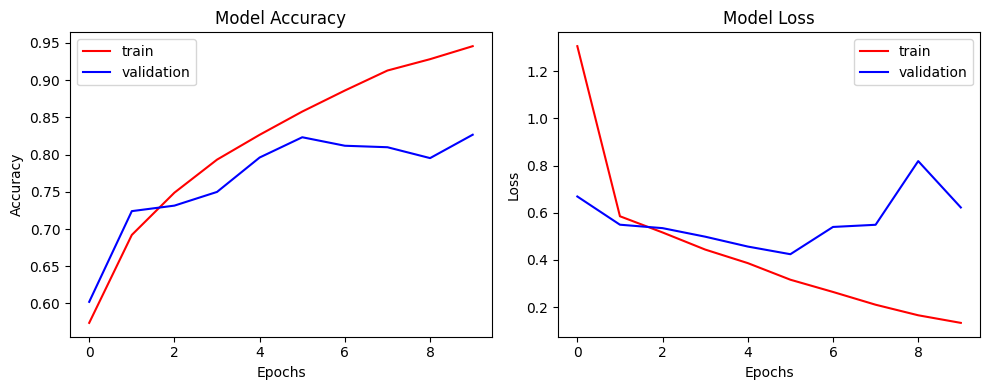

Found 50000 images in Colab.


Dropdown(description='Image:', layout=Layout(width='95%'), options=(('0. catsvsdogs/test/cats/cat.10.jpg', '/c…

Button(button_style='success', description='Predict Image', icon='check', style=ButtonStyle())

Output()

In [ ]:

# ==========================================
# 6. EVALUATION (LOSS & ACCURACY PLOTS)
# ==========================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

# Model Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Model Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


# ==========================================
# 7. INFERENCE (SELECT IMAGE FROM COLAB)
# ==========================================

from IPython.display import display
import ipywidgets as widgets

# Folders available in your Colab filesystem
base_dirs = [
    '/content/test',
    '/content/train',
    '/content/catsvsdogs'
]

# Supported image formats
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Find all images in the specified folders
image_paths = []

for base_dir in base_dirs:
    if os.path.isdir(base_dir):
        for root, dirs, files_list in os.walk(base_dir):
            for filename in files_list:
                if filename.lower().endswith(image_extensions):
                    image_paths.append(
                        os.path.join(root, filename)
                    )

# Remove duplicates and sort
image_paths = sorted(set(image_paths))

if not image_paths:
    print("No images found in the configured folders.")
    print("Check the folder paths in base_dirs.")
else:
    print(f"Found {len(image_paths)} images in Colab.")

    # Create a dropdown to select an existing image
    image_dropdown = widgets.Dropdown(
        options=[
            (f"{i}. {os.path.relpath(path, '/content')}", path)
            for i, path in enumerate(image_paths)
        ],
        description='Image:',
        layout=widgets.Layout(width='95%'),
        style={'description_width': 'initial'}
    )

    predict_button = widgets.Button(
        description='Predict Image',
        button_style='success',
        icon='check'
    )

    output_area = widgets.Output()

    def predict_image(button):
        with output_area:
            output_area.clear_output(wait=True)

            image_path = image_dropdown.value

            # Read image from Colab filesystem
            test_img = cv2.imread(image_path)

            if test_img is None:
                print("Could not read the selected image.")
                return

            # Convert BGR to RGB
            test_img = cv2.cvtColor(
                test_img, cv2.COLOR_BGR2RGB
            )

            # Display selected image
            plt.figure(figsize=(5, 5))
            plt.imshow(test_img)
            plt.title(os.path.basename(image_path))
            plt.axis('off')
            plt.show()

            # Preprocess exactly as required by the model
            test_img_resized = cv2.resize(
                test_img, (256, 256)
            )

            test_input = (
                test_img_resized.astype('float32') / 255.0
            )

            test_input = np.expand_dims(test_input, axis=0)

            # Predict
            prediction = model.predict(
                test_input, verbose=0
            )

            score = float(prediction[0][0])

            print(f"Image: {image_path}")
            print(f"Raw prediction value: {score:.4f}")

            # Assumes class 0 = CAT and class 1 = DOG
            if score < 0.5:
                print("Prediction: It's a CAT!")
                print(f"Model score: {(1 - score) * 100:.2f}%")
            else:
                print("Prediction: It's a DOG!")
                print(f"Model score: {score * 100:.2f}%")

    predict_button.on_click(predict_image)

    display(image_dropdown)
    display(predict_button)
    display(output_area)
